# 1. inspect data structure, types, missingness, outliers

In [1]:
#Load the dataset into a pandas DataFrame.
import pandas as pd
df = pd.read_csv("train.csv")

In [2]:
#Display the first five rows, dataset dimensions, column names, and data types.
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.shape

(891, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


### Identify numerical and categorical variables.
Numerical variables: Age, SibSp, Parch, and Fare.
Categorical variables: Survived, Pclass, Sex, Embarked, Name, Ticket, Cabin.
(PassengerId is a categorical idenfitier. Survived and Pclass are categorical because their numbers represent gorups rather than measured quanities)

In [5]:
#Calculate the number and percentage of missing values in each column.
df.isna().sum() #this counts missing values by column

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [6]:
df.isna().sum()/len(df)*100 #calculates missing percentage for every column

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

In [7]:
#Check for duplicate records. -- there are 0
df.duplicated().sum()

np.int64(0)

In [8]:
#Identify potential outliers in Age and Fare using the IQR method.

#Age
age_Q1 = df['Age'].quantile(0.25) #25th percentile
age_Q3 = df['Age'].quantile(0.75) #75th percentile
print(age_Q1, age_Q3)

20.125 38.0


In [9]:
a_IQR = age_Q3 - age_Q1 #calculates distance betwen q1 and q3
print(a_IQR)

17.875


In [10]:
a_lower_bound = age_Q1 - 1.5 * a_IQR 
a_upper_bound = age_Q3 + 1.5 * a_IQR
print(a_lower_bound, a_upper_bound) #outlier boundaries

-6.6875 64.8125


In [11]:
age_outliers = df[(df['Age'] < a_lower_bound) | (df['Age'] > a_upper_bound)]
age_outliers
#this is selecting ages belower the lower boundary or above the upper boundary

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
33,34,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,NaN,S
54,55,0,1,"Ostby, Mr. Engelhart Cornelius",male,65.0,0,1,113509,61.9792,B30,C
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C
116,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,NaN,Q
280,281,0,3,"Duane, Mr. Frank",male,65.0,0,0,336439,7.7500,NaN,Q
456,457,0,1,"Millet, Mr. Francis Davis",male,65.0,0,0,13509,26.5500,E38,S
493,494,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,NaN,C
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.0000,A23,S
672,673,0,2,"Mitchell, Mr. Henry Michael",male,70.0,0,0,C.A. 24580,10.5000,NaN,S
745,746,0,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0000,B22,S


In [12]:
#Fare
fare_Q1 = df['Fare'].quantile(0.25) #25th percentile
fare_Q3 = df['Fare'].quantile(0.75) #75th percentile
print(fare_Q1, fare_Q3)

7.9104 31.0


In [13]:
f_IQR = fare_Q3 - fare_Q1 #calculates distance between q1 and q3
print(f_IQR)

23.0896


In [14]:
f_lower_bound = fare_Q1 - 1.5 * f_IQR 
f_upper_bound = fare_Q3 + 1.5 * f_IQR
print(f_lower_bound, f_upper_bound) #outlier boundaries

-26.724 65.6344


In [15]:
fare_outliers = df[(df['Fare'] < f_lower_bound) | (df['Fare'] > f_upper_bound)]
fare_outliers
#this is selecting fares belower the lower boundary or above the upper boundary

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S
31,32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",female,NaN,1,0,PC 17569,146.5208,B78,C
34,35,0,1,"Meyer, Mr. Edgar Joseph",male,28.0,1,0,PC 17604,82.1708,NaN,C
52,53,1,1,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",female,49.0,1,0,PC 17572,76.7292,D33,C
...,...,...,...,...,...,...,...,...,...,...,...,...
846,847,0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.5500,NaN,S
849,850,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,NaN,1,0,17453,89.1042,C92,C
856,857,1,1,"Wick, Mrs. George Dennick (Mary Hitchcock)",female,45.0,1,1,36928,164.8667,NaN,S
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.5500,NaN,S


Findings: ‘Embarked’ had 2 missing values, ‘Age’ had 177 missing values, and ‘Cabin’ had the most missing values, with 687. There were no duplicate records. There are 11 potential outliers in ‘Age’ and 116 potential outliers in ‘Fare’. Potential outliers were retained because unusually high ages or fares may be valid observations rather than data errors.

# 2. Clean and Validate the Dataset 

In [16]:
#Create a copy of the original DataFrame before cleaning.
df_clean = df.copy()

In [17]:
#Select an appropriate strategy for handling missing values in Age, Cabin, and Embarked (retain, remove, or impute).

In [18]:
#flag missing ages while retaining the original age values
df_clean["age_missing"] = df_clean["Age"].isna()

I chose "Retain" for missing Age values because dropping those rows would also remove other useful passenger information. Leaving ages missing avoids introducing estimated values into the age distribution. 

In [19]:
df_clean["cabin_missing"] = df_clean["Cabin"].isna()

I chose to retain missing Cabin values because removing those rows would lose information for 687 passengers. I did not impute cabin numbers because there is insufficient information to determine their actual cabins.

In [20]:
df_clean["embarked_missing"] = df_clean["Embarked"].isna()

I also chose retain for missing Embarked values to preserve the passengers’ other information. Although I could fill them with the most common port, this would assume where those passengers boarded without knowing their actual ports.

In [21]:
#Investigate potential outliers and decide whether to retain, correct, or remove them.
fare_outliers[["Fare", "Pclass", "SibSp", "Parch"]].describe()

,Fare,Pclass,SibSp,Parch
count,116.000000,116.000000,116.000000,116.000000
mean,128.291629,1.163793,1.094828,0.655172
std,84.636908,0.509799,1.892679,0.885668
min,66.600000,1.000000,0.000000,0.000000
25%,78.189600,1.000000,0.000000,0.000000
50%,90.000000,1.000000,1.000000,0.000000
75%,147.778100,1.000000,1.000000,1.000000
max,512.329200,3.000000,8.000000,4.000000


In [22]:
fare_outliers["Pclass"].value_counts()

Pclass
1    104
3      7
2      5
Name: count, dtype: int64

I chose to retain both Age and Fare outliers. Age outliers are 65-80 years. Ages are plausible and there's no evidence that flagged values are errors. 104 out of 116 Fare outliers were first class travelers, which supports why the fares could be so high. 

In [23]:
#Check and correct inappropriate data types, if necessary.
df_clean.dtypes

PassengerId           int64
Survived              int64
Pclass                int64
Name                    str
Sex                     str
Age                 float64
SibSp                 int64
Parch                 int64
Ticket                  str
Fare                float64
Cabin                   str
Embarked                str
age_missing            bool
cabin_missing          bool
embarked_missing       bool
dtype: object

Data types include integers, strings, floats, and booleans. These all appear to be appropriate and suit the stored values so no corrections are necessary. Survived and Pclass are numeric codes for categories so they do not need to change. 

In [24]:
#Validate the cleaned dataset by checking missing values, duplicates, and data types again.
df_clean.isna().sum()

PassengerId           0
Survived              0
Pclass                0
Name                  0
Sex                   0
Age                 177
SibSp                 0
Parch                 0
Ticket                0
Fare                  0
Cabin               687
Embarked              2
age_missing           0
cabin_missing         0
embarked_missing      0
dtype: int64

In [25]:
df_clean.duplicated().sum()

np.int64(0)

In [26]:
df_clean.dtypes

PassengerId           int64
Survived              int64
Pclass                int64
Name                    str
Sex                     str
Age                 float64
SibSp                 int64
Parch                 int64
Ticket                  str
Fare                float64
Cabin                   str
Embarked                str
age_missing            bool
cabin_missing          bool
embarked_missing       bool
dtype: object

Missing counts remain unchanged since they were retained. No duplicates were found. Data types are appropriate, including boolean types for the new flags. 

# 3. Compute Descriptive Statistics

In [27]:
#Calculate the mean, median, minimum, maximum, range, variance, standard deviation, Q1, Q3, and IQR for Age and Fare.

In [28]:
#AGE
df_clean['Age'].agg(
    ['mean','median','min','max','var','std'])

mean       29.699118
median     28.000000
min         0.420000
max        80.000000
var       211.019125
std        14.526497
Name: Age, dtype: float64

In [29]:
#age range
df_clean['Age'].max() - df_clean['Age'].min()

np.float64(79.58)

In [30]:
#age Q1 and Q3
c_Q1 = df_clean['Age'].quantile(0.25) 
c_Q3 = df_clean['Age'].quantile(0.75) 
print(c_Q1, c_Q3)

20.125 38.0


In [31]:
#age IQR
c_IQR = c_Q3 - c_Q1
print(c_IQR)

17.875


In [32]:
#FARE
df_clean['Fare'].agg(
    ['mean','median','min','max','var','std'])

mean        32.204208
median      14.454200
min          0.000000
max        512.329200
var       2469.436846
std         49.693429
Name: Fare, dtype: float64

In [33]:
#Fare range
df_clean['Fare'].max() - df_clean['Fare'].min()

np.float64(512.3292)

In [34]:
#Fare Q1 and Q3
cf_Q1 = df_clean['Fare'].quantile(0.25) 
cf_Q3 = df_clean['Fare'].quantile(0.75) 
print(cf_Q1, cf_Q3)

7.9104 31.0


In [35]:
#Fare IQR
cf_IQR = cf_Q3 - cf_Q1
print(cf_IQR)

23.0896


In [36]:
#Calculate the frequency and percentage of observations in Sex, Pclass, and Survived.

#Sex frequency 
df_clean['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [37]:
#Sex percentage
df_clean["Sex"].value_counts() / len(df_clean) * 100

Sex
male      64.758698
female    35.241302
Name: count, dtype: float64

In [38]:
#Pclass frequence
df_clean['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [39]:
#Pclass percentage
df_clean["Pclass"].value_counts() / len(df_clean) * 100

Pclass
3    55.106622
1    24.242424
2    20.650954
Name: count, dtype: float64

In [40]:
#Survived frequency
df_clean['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [41]:
#Survived percentage
df_clean["Survived"].value_counts() / len(df_clean) * 100

Survived
0    61.616162
1    38.383838
Name: count, dtype: float64

Compare the mean and median of Age and Fare. What do these differences suggest about their distributions?

Age: mean - 29.70, median - 28.00
Fare: mean - 32.20, median - 14.45

Both means are higher than the medians. Age's mean is close to its median, while Fare's mean is more than twice its median, suggesting stronger right skew in Fare. High values can pull the mean upward more than the median. The median better represents a typical fare.

In [42]:
#Compare the average Fare across passenger classes.
df_clean.groupby("Pclass")["Fare"].mean()

Pclass
1    84.154687
2    20.662183
3    13.675550
Name: Fare, dtype: float64

First-class passengers had the highest average fare, followed by second class, then third class.

Briefly interpret your findings.

Passengers with recorded ages had a mean age of 29.70 years and a median of 28 years, which is a mild right skew. Fare had a stronger right skew because some unusually high fares pulled the mean above the median. Most passengers in the dataset were male (64.76%) and traveled in third class (55.11%), and 38.38% survived. Average fares were highest in first class (84.15), followed by second class (20.66) and third class (13.68). Age statistics exclude 177 missing values, so they may not fully represent all passengers.

# 4. Visualize Patterns and Investigate Anomalies 

In [43]:
import matplotlib.pyplot as plt

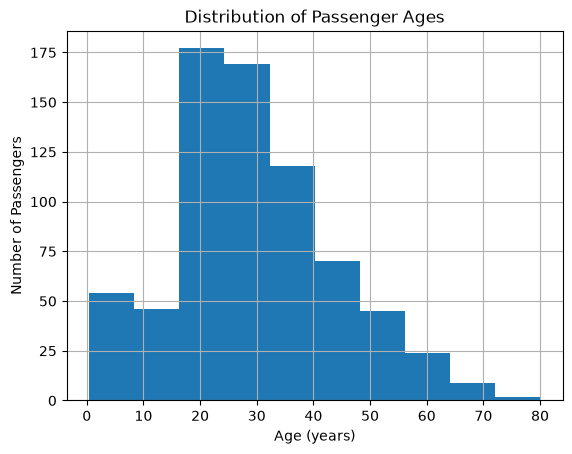

In [44]:
#Histogram: Visualize the distribution of Age.
df_clean['Age'].hist()
plt.title('Distribution of Passenger Ages')
plt.xlabel('Age (years)')
plt.ylabel('Number of Passengers')
plt.show()

The tallest bars are ages 16-32, there are more younger passengers than older passengers. Ages 65-80 are unusual but plausible. The 177 missing ages aren't plotted. The distribution is right-skewed. Investigation into the missing ages could help assess bias.

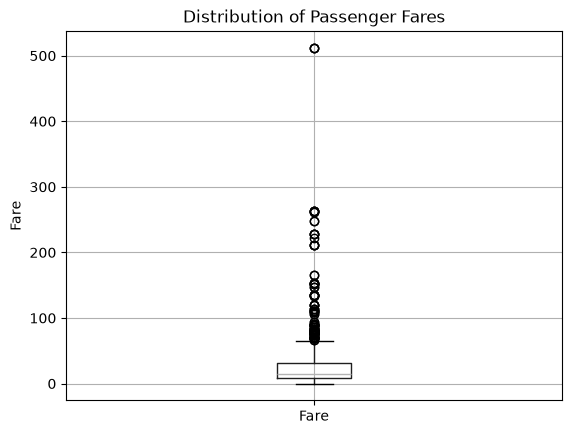

In [45]:
#Boxplot: Visualize Fare and identify potential outliers.
df_clean.boxplot(column='Fare')
plt.title('Distribution of Passenger Fares')
plt.ylabel('Fare')
plt.show()

Most fares are low, with 50% between 7.91 and 31.00 with median of 14.45. IQR showed 116 high fares, and some outlier points overlap on the plot. 104 of the flagged high fares were first class. There is a strong right skew in Fare and the extreme fare is near 512.33. Investigation of ticket records could explain the large fares.

In [46]:
#Bar chart: Compare the number of passengers across passenger classes.
df_clean['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

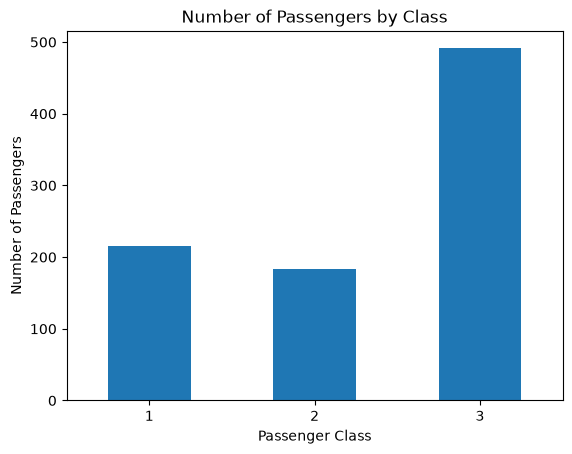

In [47]:
df_clean['Pclass'].value_counts().sort_index().plot.bar()
plt.title('Number of Passengers by Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=0)
plt.show()

Third class had the most passengers at 491. First class had 216, and second class had 184. No obvious anomaly requiring further investigation. 

In [48]:
#Grouped bar chart: Compare survival rates across Sex or Pclass.
survival_rates = pd.crosstab(df_clean['Pclass'], df_clean['Survived'], normalize = 'index') * 100
survival_rates

Survived,0,1
Pclass,,
1,37.037037,62.962963
2,52.717391,47.282609
3,75.763747,24.236253


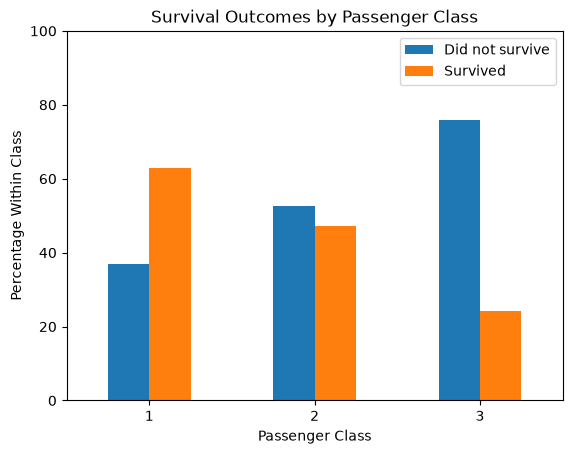

In [49]:
survival_rates.plot.bar()
plt.title('Survival Outcomes by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Percentage Within Class')
plt.legend(['Did not survive','Survived'])
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

First class had the highest survival rate and third class had the lowest. Investigation including sex and age within each class could help explain differences. 

The dataset includes 891 passengers and 12 columns with no duplicate records. There were 177 missing age values, 687 missing cabin values, and 2 missing embarked values. There were 11 potential outliers in Age and 116 in Fare. Recorded ages averaged 29.70 years, with a median of 28. Fare was strongly right-skewed, with a mean of 32.20 and a median of 14.45. Third class had the most passengers (491), and first class had the highest average fare (84.15) and survival rate (62.96%). There might not be a complete picture due to missing passenger information and further investigation would be needed to understand the differences in survival rates across the classes.